#  Appel de fonctions (function calling) avec l'API Gemini

Bienvenue dans ce nouveau notebook du cours sur l'IA générative.

Dans ce notebook, vous allez utiliser l'appel de fonctions automatique de l'API Gemini pour créer une interface de chat au-dessus d'une base de données locale. Cet exemple est un jouet : il lui manque de nombreuses protections de sûreté et de sécurité qu'on mettrait en place dans un vrai projet. Il montre cependant à quel point il est simple d'ajouter une interface conversationnelle à une application existante.

> **Version adaptée pour Google Colab** : ce notebook est en français, lit la clé API depuis les **secrets Colab**, relance automatiquement les appels en cas de quota atteint et utilise le modèle `gemini-3.1-flash-lite` (les modèles Gemini 2.0 d'origine ont été arrêtés). La dernière partie (API Live) a été adaptée au modèle `gemini-3.8-live`, qui n'exécute plus de code : voir les explications dans cette section.

## Configuration

Commencez par installer et importer le SDK Python. On installe aussi `jupysql`, qui fournit les commandes magiques `%sql` utilisées plus bas.

In [ ]:
# Mise à jour du SDK Google GenAI pour utiliser les derniers modèles Gemini.
# Installation de Jupysql pour pouvoir exécuter des requêtes SQL directement avec des commandes magiques.
!pip install -U -q "google-genai" "jupysql"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 kB 738.7 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.1/95.1 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 262.5/262.5 kB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 192.8/192.8 kB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 810.6/810.6 kB 18.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.59.0 which is incompatible.


In [ ]:
from google import genai
from google.genai import types

# Affichage de la version pour s'assurer que la mise à jour s'est bien déroulée.
print(f"Version du SDK GenAI : {genai.__version__}")

# Définition du modèle standard léger utilisé pour l'appel de fonctions classique.
MODEL = "gemini-3.1-flash-lite"

### Configurer votre clé API

Pour exécuter la cellule suivante, votre clé API doit être enregistrée dans un [secret Colab](https://colab.research.google.com/notebooks/secrets.ipynb) nommé `GOOGLE_API_KEY` :

1. Dans la barre latérale gauche de Colab, cliquez sur l'icône **clé** 🔑 (« Secrets »).
2. Cliquez sur **Ajouter un secret**, saisissez `GOOGLE_API_KEY` comme nom et collez votre clé comme valeur.
3. Activez l'interrupteur **Accès au notebook**.

Si vous n'avez pas encore de clé API, vous pouvez en obtenir une sur [AI Studio](https://aistudio.google.com/app/apikey). Vous trouverez des [instructions détaillées dans la documentation](https://ai.google.dev/gemini-api/docs/api-key).

Hors de Colab (exécution locale, VM…), la cellule utilise la variable d'environnement `GOOGLE_API_KEY`.

In [ ]:
import os

GOOGLE_API_KEY = None

# Étape 1 : Tentative de récupération de la clé API depuis les secrets de Colab
try:
    from google.colab import userdata
    GOOGLE_API_KEY = userdata.get("GOOGLE_API_KEY")
except ImportError:
    pass  # Ignoré si le notebook est exécuté en dehors de Google Colab

# Étape 2 : Alternative via les variables d'environnement (ex: exécution locale)
if not GOOGLE_API_KEY:
    GOOGLE_API_KEY = os.environ.get("GOOGLE_API_KEY")

# Étape 3 : Blocage si aucune clé n'est configurée
if not GOOGLE_API_KEY:
    raise ValueError(
        "Clé API introuvable : ajoutez un secret Colab nommé GOOGLE_API_KEY "
        "et activez « Accès au notebook »."
    )

print("Clé API chargée ✅")

Clé API chargée ✅


Si vous obtenez une erreur du type `SecretNotFoundError` ou `NotebookAccessError`, vérifiez que le secret s'appelle exactement `GOOGLE_API_KEY` **et** que l'interrupteur **Accès au notebook** est activé dans le panneau Secrets (icône clé). Colab peut aussi afficher une fenêtre vous demandant d'autoriser l'accès : cliquez sur **Autoriser l'accès**.

### Politique de nouvelle tentative (retry)

Le modèle peut enchaîner automatiquement plusieurs appels pour une question complexe. En cas d'erreur 429 (quota) ou 503 (modèle surchargé), l'appel est relancé automatiquement après 2 s, 4 s, 8 s… pendant 60 s au maximum. Il n'y a aucune attente quand l'appel réussit.

> **Clé gratuite** : le tier gratuit est partagé et peut être saturé pendant le cours. Si une cellule met un peu de temps à répondre, c'est normal : laissez le retry faire son travail. Si l'erreur persiste après 60 s, relancez simplement la cellule.

In [ ]:
from google.api_core import retry

# Prédicat pour identifier les codes d'erreur de quota (429) ou de surcharge serveur (503)
is_retriable = lambda e: (isinstance(e, genai.errors.APIError) and e.code in {429, 503})

# Configuration de la stratégie d'attente exponentielle (Backoff) :
# d'abord 2s, puis 4s, 8s... jusqu'à 15s max entre chaque essai, pour un total de 60s.
politique_retry = retry.Retry(predicate=is_retriable, initial=2, maximum=15, timeout=60)

# Sauvegarde de la méthode originale pour éviter des surcouches successives lors des réexécutions.
if not hasattr(genai.models.Models, "_generate_original"):
    genai.models.Models._generate_original = genai.models.Models.generate_content

# Surcharge de la méthode generate_content pour y intégrer automatiquement la logique de retry.
genai.models.Models.generate_content = politique_retry(genai.models.Models._generate_original)

## Créer une base de données locale

Pour cet exemple minimal, vous allez créer une base SQLite locale et y ajouter quelques données synthétiques, pour avoir quelque chose à interroger.

Chargez l'extension IPython `sql` pour manipuler la base avec des commandes magiques (les instructions `%`) et créer une nouvelle base SQLite vide.

In [ ]:
# Chargement de l'extension SQL pour activer l'utilisation des magics %sql et %%sql
%load_ext sql
# Connexion (et création si elle n'existe pas) à la base de données SQLite locale 'sample.db'
%sql sqlite:///sample.db

Connecting to 'sqlite:///sample.db'

Créez les tables et insérez quelques données synthétiques. N'hésitez pas à modifier cette structure et ces données.

In [ ]:
%%sql
-- Crée la table 'products' (produits)
CREATE TABLE IF NOT EXISTS products (
  	product_id INTEGER PRIMARY KEY AUTOINCREMENT,
  	product_name VARCHAR(255) NOT NULL,
  	price DECIMAL(10, 2) NOT NULL
  );

-- Crée la table 'staff' (personnel)
CREATE TABLE IF NOT EXISTS staff (
  	staff_id INTEGER PRIMARY KEY AUTOINCREMENT,
  	first_name VARCHAR(255) NOT NULL,
  	last_name VARCHAR(255) NOT NULL
  );

-- Crée la table 'orders' (commandes)
CREATE TABLE IF NOT EXISTS orders (
  	order_id INTEGER PRIMARY KEY AUTOINCREMENT,
  	customer_name VARCHAR(255) NOT NULL,
  	staff_id INTEGER NOT NULL,
  	product_id INTEGER NOT NULL,
  	FOREIGN KEY (staff_id) REFERENCES staff (staff_id),
  	FOREIGN KEY (product_id) REFERENCES products (product_id)
  );

-- Insère des données dans la table 'products'
INSERT INTO products (product_name, price) VALUES
  	('Laptop', 799.99),
  	('Keyboard', 129.99),
  	('Mouse', 29.99);

-- Insère des données dans la table 'staff'
INSERT INTO staff (first_name, last_name) VALUES
  	('Alice', 'Smith'),
  	('Bob', 'Johnson'),
  	('Charlie', 'Williams');

-- Insère des données dans la table 'orders'
INSERT INTO orders (customer_name, staff_id, product_id) VALUES
  	('David Lee', 1, 1),
  	('Emily Chen', 2, 2),
  	('Frank Brown', 1, 3);

Running query in 'sqlite:///sample.db'

3 rows affected.

3 rows affected.

3 rows affected.

++
||
++
++

## Définir les fonctions d'accès à la base

Avec le SDK Python de l'API Gemini, on peut mettre en place l'appel de fonctions en définissant [un schéma OpenAPI](https://ai.google.dev/api/caching#Schema) transmis au modèle. On peut aussi définir des fonctions Python et laisser le SDK les inspecter pour générer le schéma automatiquement. Dans ce second cas, il est important que les fonctions aient des annotations de type et des docstrings précises qui décrivent ce qu'elles font : le modèle ne voit pas le corps des fonctions, la documentation sert donc d'interface.

En fournissant trois fonctionnalités clés (lister les tables, décrire une table et exécuter une requête), le LLM dispose, comme un utilisateur humain, des outils de base pour comprendre et interroger la base.

Commencez par une connexion à la base, qui sera utilisée par toutes les fonctions.

In [ ]:
import sqlite3

# Initialisation d'une connexion permanente à notre base de données SQLite locale.
# Cette connexion sera partagée par les différentes fonctions Python exposées au modèle.
db_file = "sample.db"
db_conn = sqlite3.connect(db_file)

La première fonction liste toutes les tables de la base. Définissez-la, puis testez-la pour vérifier qu'elle fonctionne.

In [ ]:
def list_tables() -> list[str]:
    """Retrieve the names of all tables in the database."""
    # Note : La docstring est rédigée en anglais car elle sert de description directe
    # pour guider le modèle LLM lorsqu'il doit choisir cet outil.
    print(' - DB CALL: list_tables()')

    cursor = db_conn.cursor()
    # Requête système SQLite pour lister les tables définies par l'utilisateur
    cursor.execute("SELECT name FROM sqlite_master WHERE type='table';")

    tables = cursor.fetchall()
    return [t[0] for t in tables]

# Test de la fonction pour vérifier la liste de nos tables
list_tables()

 - DB CALL: list_tables()


['products', 'sqlite_sequence', 'staff', 'orders']

Une fois les tables connues, un utilisateur de la base a ensuite besoin de connaître les colonnes d'une table. Définissez cette fonction aussi, et vérifiez qu'elle fonctionne.

In [ ]:
def describe_table(table_name: str) -> list[tuple[str, str]]:
    """Look up the table schema.

    Returns:
      List of columns, where each entry is a tuple of (column, type).
    """
    # Le modèle utilisera cette fonction pour comprendre les champs d'une table cible
    print(f' - DB CALL: describe_table({table_name})')

    cursor = db_conn.cursor()
    # PRAGMA table_info retourne des informations sur les colonnes (nom, type, etc.)
    cursor.execute(f"PRAGMA table_info({table_name});")

    schema = cursor.fetchall()
    # On extrait uniquement le nom de la colonne (index 1) et son type (index 2)
    return [(col[1], col[2]) for col in schema]

# Test de récupération de la structure de la table 'products'
describe_table("products")

 - DB CALL: describe_table(products)


[('product_id', 'INTEGER'),
 ('product_name', 'VARCHAR(255)'),
 ('price', 'DECIMAL(10, 2)')]

Le système connaît maintenant les tables et les colonnes : il a assez d'informations pour générer et exécuter une requête `SELECT`. Ajoutez cette fonctionnalité et testez-la.

In [ ]:
def execute_query(sql: str) -> list[list[str]]:
    """Execute an SQL statement, returning the results."""
    # Cette fonction permet au modèle d'exécuter la requête SQL finale
    # générée à partir de la question de l'utilisateur.
    print(f' - DB CALL: execute_query({sql})')

    cursor = db_conn.cursor()
    cursor.execute(sql)
    return cursor.fetchall()

# Test de lecture de l'ensemble de la table 'products'
execute_query("select * from products")

 - DB CALL: execute_query(select * from products)


[(1, 'Laptop', 799.99), (2, 'Keyboard', 129.99), (3, 'Mouse', 29.99)]

## Mettre en place les appels de fonctions

Vous pouvez maintenant tout assembler dans un appel à l'API Gemini.

L'appel de fonctions fonctionne en ajoutant des messages spécifiques à une session de chat. Quand des schémas de fonctions sont définis et mis à disposition du modèle, celui-ci peut, au lieu de répondre par du texte, renvoyer un `function_call`. Le client doit alors répondre avec un `function_response` contenant le résultat de l'appel, puis la conversation continue normalement.

Normalement, cette interaction se fait manuellement : vous, le client, pouvez valider puis lancer l'appel. Mais le SDK Python prend aussi en charge l'**appel de fonctions automatique**, où les fonctions fournies sont invoquées automatiquement. C'est une fonctionnalité puissante, à utiliser avec précaution, par exemple uniquement avec des fonctions sans [effets de bord](https://fr.wikipedia.org/wiki/Effet_de_bord_(informatique)).

Voici le diagramme d'états du déroulement d'une conversation avec appel de fonctions. En mode automatique, la ligne du bas est exécutée automatiquement par le SDK Python. En mode manuel, c'est vous qui écrivez le code de chaque étape.

![Diagramme d'états de l'appel de fonctions](https://codelabs.developers.google.com/static/codelabs/gemini-function-calling/img/gemini-function-calling-overview_1440.png)

L'instruction système reste en anglais, comme les données de la base. Vous pouvez la traduire et poser vos questions en français : le modèle s'adapte.

In [ ]:
# Liste des fonctions Python que nous autorisons le LLM à appeler directement.
db_tools = [list_tables, describe_table, execute_query]

# Instructions système dictant le rôle du chatbot et la manière d'utiliser les outils.
instruction = """You are a helpful chatbot that can interact with an SQL database
for a computer store. You will take the users questions and turn them into SQL
queries using the tools available. Once you have the information you need, you will
answer the user's question using the data returned.

Use list_tables to see what tables are present, describe_table to understand the
schema, and execute_query to issue an SQL SELECT query."""

# Initialisation du client principal avec la clé API récupérée
client = genai.Client(api_key=GOOGLE_API_KEY)

# Création de la session de chat. En passant `db_tools` dans le paramètre `tools`,
# le SDK de Gemini gérera l'appel de fonction de manière transparente (mode automatique).
chat = client.chats.create(
    model=MODEL,
    config=types.GenerateContentConfig(
        system_instruction=instruction,
        tools=db_tools,
    ),
)

Vous pouvez maintenant discuter avec le modèle et l'interroger sur le contenu de la base (« Quel est le produit le moins cher ? »).

In [ ]:
# Envoi d'une question nécessitant plusieurs appels d'outils automatiques pour y répondre.
resp = chat.send_message("What is the cheapest product?")
print(f"\n{resp.text}")

 - DB CALL: list_tables()
 - DB CALL: describe_table(products)
 - DB CALL: execute_query(SELECT product_name, price FROM products ORDER BY price ASC LIMIT 1;)

The cheapest product is the Mouse, which costs 29.99.


Explorez la session de chat et posez vos propres questions. Les modèles Gemini récents sont assez performants et peuvent généralement répondre à des questions qui demandent plusieurs étapes. Ici : « Sur quels produits la commerciale Alice devrait-elle se concentrer pour compléter son portefeuille ? Expliquez pourquoi. »

In [ ]:
# Initialisation d'un nouveau chat vierge pour notre seconde démonstration.
chat = client.chats.create(
    model=MODEL,
    config=types.GenerateContentConfig(
        system_instruction=instruction,
        tools=db_tools,
    ),
)

# Envoi d'une question d'analyse plus complexe qui va inciter le modèle à
# explorer la structure de toutes les tables avant de formuler une requête jointe complexe.
response = chat.send_message('What products should salesperson Alice focus on to round out her portfolio? Explain why.')
print(f"\n{response.text}")

 - DB CALL: list_tables()
 - DB CALL: describe_table(products)
 - DB CALL: describe_table(staff)
 - DB CALL: describe_table(orders)
 - DB CALL: execute_query(SELECT * FROM staff WHERE first_name = 'Alice')
 - DB CALL: execute_query(SELECT p.product_name 
FROM products p
WHERE p.product_id NOT IN (
    SELECT o.product_id 
    FROM orders o 
    JOIN staff s ON o.staff_id = s.staff_id 
    WHERE s.first_name = 'Alice'
))
 - DB CALL: execute_query(SELECT p.product_name, COUNT(o.order_id) as total_sales
FROM products p
LEFT JOIN orders o ON p.product_id = o.product_id
GROUP BY p.product_id)
 - DB CALL: execute_query(SELECT p.product_name, s.first_name
FROM products p
JOIN orders o ON p.product_id = o.product_id
JOIN staff s ON o.staff_id = s.staff_id)

Alice currently has sales for **Laptops** and **Mice**, but she has not sold any **Keyboards**. 

To round out her portfolio, Alice should focus on selling **Keyboards**. This will help her gain experience across the full range of products 

### Examiner la conversation

Pour voir les appels effectués par le modèle et ce que le client renvoie, vous pouvez examiner l'historique du chat. Cette fonction utilitaire affiche chaque tour de parole avec les champs transmis ou renvoyés.

In [ ]:
import textwrap


def print_chat_turns(chat):
    """Affiche chaque tour de l'historique du chat, y compris les appels de fonctions et leurs réponses."""
    # Cette fonction permet de visualiser la structure interne de l'historique.
    # On peut y voir comment le modèle alterne entre requêtes d'appels de fonction (function_call)
    # et l'envoi de résultats retournés par notre client python (function_response).
    for event in chat.get_history():
        print(f"{event.role.capitalize()}:")

        for part in event.parts:
            if txt := part.text:
                print(f'  "{txt}"')
            elif fn := part.function_call:
                args = ", ".join(f"{key}={val}" for key, val in fn.args.items())
                print(f"  Appel de fonction : {fn.name}({args})")
            elif resp := part.function_response:
                print("  Réponse de la fonction :")
                print(textwrap.indent(str(resp.response['result']), "    "))

        print()

# Affichage du déroulé complet de la conversation précédente.
print_chat_turns(chat)

User:
  "What products should salesperson Alice focus on to round out her portfolio? Explain why."

Model:
  Appel de fonction : list_tables()

User:
  Réponse de la fonction :
    ['products', 'sqlite_sequence', 'staff', 'orders']

Model:
  Appel de fonction : describe_table(table_name=products)

User:
  Réponse de la fonction :
    [('product_id', 'INTEGER'), ('product_name', 'VARCHAR(255)'), ('price', 'DECIMAL(10, 2)')]

Model:
  Appel de fonction : describe_table(table_name=staff)

User:
  Réponse de la fonction :
    [('staff_id', 'INTEGER'), ('first_name', 'VARCHAR(255)'), ('last_name', 'VARCHAR(255)')]

Model:
  Appel de fonction : describe_table(table_name=orders)

User:
  Réponse de la fonction :
    [('order_id', 'INTEGER'), ('customer_name', 'VARCHAR(255)'), ('staff_id', 'INTEGER'), ('product_id', 'INTEGER')]

Model:
  Appel de fonction : execute_query(sql=SELECT * FROM staff WHERE first_name = 'Alice')

User:
  Réponse de la fonction :
    [(1, 'Alice', 'Smith')]

Model:
  

Dans cette sortie, vous voyez chacun des tours de la conversation. Le modèle ne se souvient de rien en dehors de l'historique du chat : vous pouvez donc modifier la structure ou les données de la base, et le modèle s'adaptera sans changer le code. Essayez !

## Appels de fonctions en temps réel avec l'API Live

L'API Live est un service de streaming bidirectionnel (conçu à l'origine pour la voix et la vidéo en temps réel). Tout est configuré à l'avance, puis exécuté : c'est un peu plus complexe, mais cela permet de voir le modèle enchaîner lui-même plusieurs appels d'outils pour accomplir une tâche.

> **Adaptation** : le notebook d'origine utilisait `gemini-2.0-flash-exp`, qui pouvait écrire et exécuter du code appelant vos fonctions (« appel de fonctions compositionnel »). Ce modèle a été arrêté, et le modèle Live actuel, `gemini-3.8-live`, ne prend pas en charge l'exécution de code. Il prend en revanche en charge l'appel de fonctions : il enchaîne donc les appels à `execute_query` directement, sans passer par du code. Le tracé du graphique est confié au modèle standard, qui, lui, sait exécuter du code.
>
> Le retry configuré plus haut ne s'applique pas à l'API Live. Si la connexion échoue (quota, modèle indisponible avec une clé gratuite), relancez la cellule un peu plus tard.

Commencez par définir une fonction qui gère la sortie du modèle en streaming : elle affiche le texte, exécute les appels d'outils et renvoie leurs résultats au modèle.

In [ ]:
from IPython.display import display, Image, Markdown


async def handle_response(session, tool_impl=None):
  """Affiche la sortie en streaming et gère les appels d'outils pendant la session Live."""
  # L'API Live envoie les données de façon asynchrone et continue.
  # Cette fonction écoute le flux d'événements entrant (session.receive()).
  all_responses = []
  texte = ""

  async for msg in session.receive():
    all_responses.append(msg)

    # Cas 1 : Réception de morceaux de texte (le modèle nous parle)
    if text := msg.text:
      if not texte:
        # Premier bloc de texte reçu : on affiche un titre pour structurer l'affichage
        display(Markdown('### Texte'))
      texte += text
      print(text, end='')

    # Cas 2 : Le modèle demande l'exécution d'un ou plusieurs outils
    elif tool_call := msg.tool_call:
      reponses = []
      for fc in tool_call.function_calls:
        display(Markdown(f'### Appel d\'outil : `{fc.name}`'))

        # On exécute localement la fonction associée (ex: execute_query)
        if callable(tool_impl):
          try:
            result = tool_impl(**fc.args)
          except Exception as e:
            result = str(e)
        else:
          result = 'ok'

        # Préparation de l'objet de réponse structuré selon l'API Gemini
        reponses.append(types.FunctionResponse(
            name=fc.name,
            id=fc.id,
            response={'result': result},
        ))

      # Envoi immédiat des résultats des outils au modèle pour qu'il puisse continuer son travail
      await session.send_tool_response(function_responses=reponses)

  print()
  return texte

### Chat textuel en direct avec la base de données

Connectez-vous maintenant au modèle et démarrez une conversation.

L'API Live est une API de streaming : cet exemple est entièrement scripté et ne contient qu'une seule demande de l'utilisateur (« Générez et insérez 5 nouvelles lignes dans la table des commandes »). Le modèle doit malgré tout faire plusieurs allers-retours pour interroger la base : vous devriez le voir appeler l'outil `execute_query` plusieurs fois.

L'outil est déclaré en mode `BLOCKING` : le modèle attend le résultat de chaque requête avant de continuer (avec `gemini-3.8-live`, les appels sont asynchrones par défaut).

In [ ]:
LIVE_MODEL = "gemini-3.8-live"
live_client = genai.Client(api_key=GOOGLE_API_KEY)

# Déclaration de l'outil execute_query auprès du client Live.
execute_query_tool_def = types.FunctionDeclaration.from_callable(
    client=live_client, callable=execute_query)

# Configuration importante : le modèle doit s'interrompre et attendre le retour de notre
# exécution SQL (BLOCKING) avant de poursuivre la génération du flux.
execute_query_tool_def.behavior = types.Behavior.BLOCKING

# Instructions adaptées pour l'interface de base de données en direct.
sys_int = """You are a database interface. Use the `execute_query` function
to answer the users questions by looking up information in the database,
running any necessary queries and responding to the user.

You need to look up table schema using sqlite3 syntax SQL, then once an
answer is found be sure to tell the user. If the user is requesting an
action, you must also execute the actions.
"""

# Configuration de la session de connexion en temps réel avec le format audio obligatoire
config = types.LiveConnectConfig(
    response_modalities=["AUDIO"],
    system_instruction=sys_int,
    tools=[types.Tool(function_declarations=[execute_query_tool_def])],
)


async def envoyer(session, message):
  """Envoie un message utilisateur et affiche la réponse du modèle."""
  print(f"> {message}\n")
  await session.send_client_content(
      turns=types.Content(role="user", parts=[types.Part(text=message)]),
      turn_complete=True,
  )
  return await handle_response(session, tool_impl=execute_query)

# Alerte de sécurité sur le format de clé pour les connexions Live WebSocket
if not GOOGLE_API_KEY or GOOGLE_API_KEY.startswith("AQ") is False:
    print("⚠️ Attention : Votre clé API semble incorrecte ou invalide pour l'API Live. Veuillez vérifier vos secrets Colab.")

try:
    # Initialisation de la connexion asynchrone bidirectionnelle
    async with live_client.aio.live.connect(model=LIVE_MODEL, config=config) as session:
        # On demande au modèle d'insérer des données d'exemple
        await envoyer(session, "Please generate and insert 5 new rows in the orders table.")
except Exception as e:
    print(f"\n❌ Erreur lors de la connexion : {e}")
    print("Conseil : Vérifiez que votre clé API est valide et que le service Live est disponible dans votre région.")

> Please generate and insert 5 new rows in the orders table.



### Appel d'outil : `execute_query`

 - DB CALL: execute_query(PRAGMA table_info(orders);)


### Appel d'outil : `execute_query`

 - DB CALL: execute_query(SELECT name FROM sqlite_master WHERE type='table';)


...

 - DB CALL: execute_query(SELECT staff_id FROM staff LIMIT 1;)


### Appel d'outil : `execute_query`

 - DB CALL: execute_query(SELECT product_id FROM products LIMIT 1;)


### Appel d'outil : `execute_query`

 - DB CALL: execute_query(INSERT INTO orders (customer_name, staff_id, product_id) VALUES 
('Alice Smith', 1, 1),
('Bob Jones', 1, 1),
('Charlie Brown', 1, 1),
('Diana Prince', 1, 1),
('Edward Norton', 1, 1);)


Dans la sortie de l'étape précédente, vous devriez voir plusieurs sections « Appel d'outil » : le modèle consulte d'abord le schéma, puis insère les lignes une par une (ou en une seule requête), avant de confirmer à l'utilisateur.

Vous pouvez vérifier le résultat directement dans la base :

In [ ]:
# Vérification directe en interrogeant la table 'orders' pour constater
# les ajouts effectués de manière dynamique par le modèle Live.
execute_query("select * from orders")

 - DB CALL: execute_query(select * from orders)


[(1, 'David Lee', 1, 1),
 (2, 'Emily Chen', 2, 2),
 (3, 'Frank Brown', 1, 3),
 (4, 'Alice Smith', 1, 1),
 (5, 'Bob Jones', 1, 1),
 (6, 'Charlie Brown', 1, 1),
 (7, 'Diana Prince', 1, 1),
 (8, 'Edward Norton', 1, 1)]

### Tracer un graphique à partir de la base

Essayez l'exemple suivant. Le modèle Live répond d'abord à la question « Pouvez-vous calculer le nombre de commandes passées par chaque membre du personnel ? » en interrogeant la base. Il arrive que le modèle devine mal le schéma : observez la sortie `Texte` pour le voir analyser l'erreur, essayer une autre approche et corriger sa requête.

Ensuite, comme `gemini-3.8-live` ne sait pas exécuter de code, on transmet sa réponse au modèle standard avec l'outil d'**exécution de code**, pour qu'il génère et exécute du code Python qui trace un graphique seaborn.

Si le modèle ne renvoie pas de graphique, relancez la cellule.

> Can you figure out the number of orders that were made by each of the staff?



### Appel d'outil : `execute_query`

 - DB CALL: execute_query(SELECT name FROM sqlite_master WHERE type='table';)


### Appel d'outil : `execute_query`

 - DB CALL: execute_query(PRAGMA table_info(staff);)


...

 - DB CALL: execute_query(PRAGMA table_info(orders);)


### Appel d'outil : `execute_query`

 - DB CALL: execute_query(SELECT s.first_name, s.last_name, COUNT(o.order_id) AS order_count FROM staff s LEFT JOIN orders o ON s.staff_id = o.staff_id GROUP BY s.staff_id;)


### Code
```python
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import io

# Data provided
data = """
Category,Value
A,10
B,25
C,15
D,30
E,20
"""

# Read the data
df = pd.read_csv(io.StringIO(data.strip()))

# Plotting
plt.figure(figsize=(8, 6))
sns.set_theme(style="whitegrid")
plot = sns.barplot(x='Category', y='Value', data=df, palette='viridis')

# Adding labels and title
plot.set_title('Category vs Value')
plot.set_xlabel('Category')
plot.set_ylabel('Value')

# Save the plot
plt.savefig('seaborn_chart.png')
plt.show()

```

### Résultat : Outcome.OUTCOME_OK
```
None
```

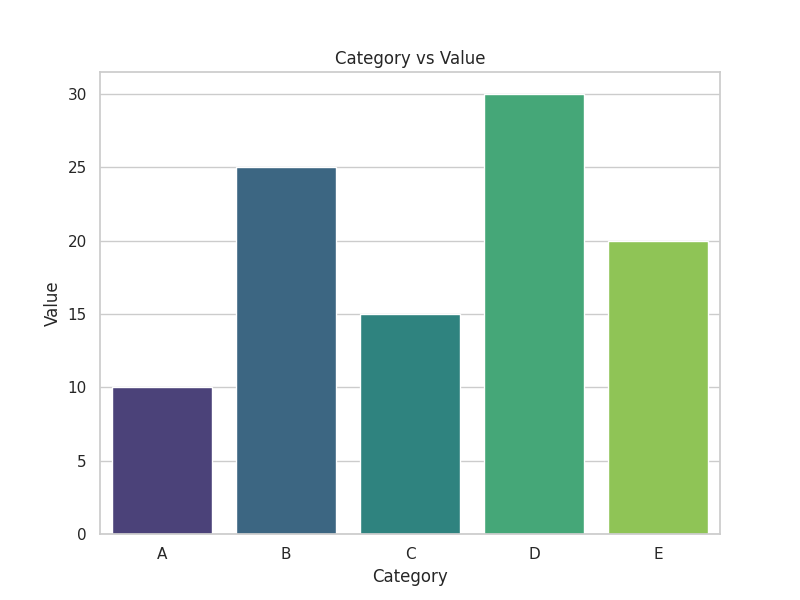

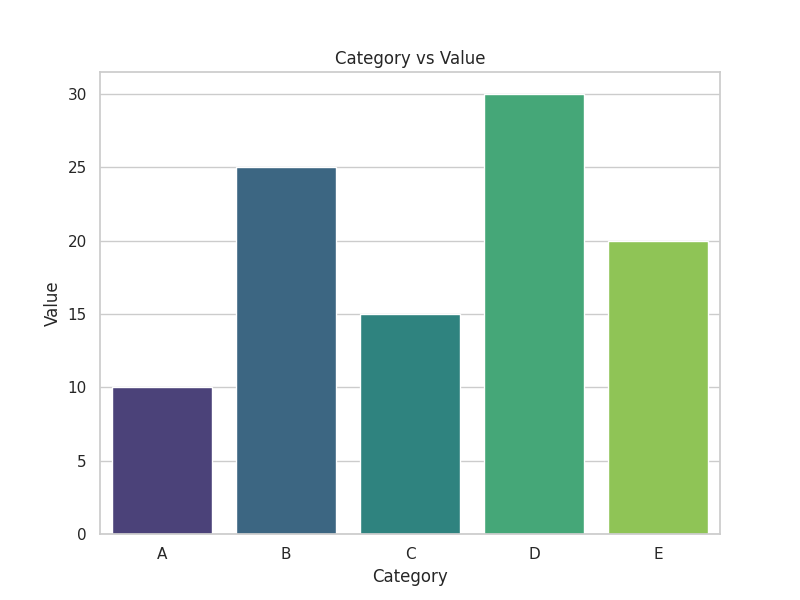

I have generated and plotted the data using Seaborn. The bar chart visualization is shown above.

In [ ]:
async with live_client.aio.live.connect(model=LIVE_MODEL, config=config) as session:
  # Étape 1 : Le modèle Live analyse et calcule le nombre de commandes par personnel
  resultat = await envoyer(
      session, "Can you figure out the number of orders that were made by each of the staff?")

# Étape 2 : Transmission du résultat textuel extrait de la base au modèle standard.
# On lui demande de générer et d'exécuter du code Python via l'outil 'code_execution'
# natif de Gemini pour obtenir le tracé du graphique seaborn.
response = client.models.generate_content(
    model=MODEL,
    contents=f"Here is some data from a database:\n\n{resultat}\n\n"
             "Generate and run some code to plot this as a python seaborn chart.",
    config=types.GenerateContentConfig(
        tools=[types.Tool(code_execution=types.ToolCodeExecution())],
    ),
)

# Étape 3 : Parcours des différentes parties de la réponse pour afficher le texte explicatif,
# le code source généré par l'outil, le résultat d'exécution et enfin l'image finale.
for part in response.candidates[0].content.parts:
  if part.text:
    display(Markdown(part.text))
  elif part.executable_code:
    display(Markdown(f'### Code\n```python\n{part.executable_code.code}\n```'))
  elif part.code_execution_result:
    display(Markdown(f'### Résultat : {part.code_execution_result.outcome}\n'
                     f'```\n{part.code_execution_result.output}\n```'))
  elif part.inline_data:
    display(Image(part.inline_data.data))